# ECG biometrics across recording sessions
*Signal Analysis and Representations — reproducible project notebook*

Can a single-channel ECG identify a person or verify a claimed identity across sessions? We compare handcrafted features + PCA, a 1D-CNN, cross-correlation and DTW. We also test how CNN training with augmentation changes the results under drift and band-limited noise.

Run all cells in order from the repository root with the project Python kernel. See [README](README.md) for installation and [REPORT](REPORT.md) for the short course report. The notebook uses the existing `ecg` package for experiments; its saved outputs contain only aggregate results and a **synthetic** waveform example.

- **auto**: reuse the verified reference runs if present; otherwise run the full pipeline.
- **full**: regenerate preprocessing, split manifests, models and all evaluations under `runs/notebook/full`, without overwriting the reference runs.
- **smoke**: run Heartprint end to end with one CNN epoch and smaller galleries; useful on CPU. The resulting figures are for checking the pipeline, not reproducing the report.

On a clean checkout, set the local archive paths below or place extracted datasets under `data/raw/`. Network downloads are opt-in.

In [1]:
from pathlib import Path
import json
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import roc_curve

from ecg.augment import perturb, query_rng
from ecg.preprocess import SAMPLE_RATE, prepare_signal, r_peaks, read_csv
from ecg.sources import list_records
from ecg.splits import validate_split

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").is_file() or not (ROOT / "ecg").is_dir():
    raise RuntimeError("Start the notebook kernel from the ECG repository root.")

MODE = os.environ.get("ECG_NOTEBOOK_MODE", "auto")  # auto | full | smoke
DEVICE = os.environ.get("ECG_NOTEBOOK_DEVICE", "auto")  # auto | cpu | mps | cuda
DOWNLOAD_MISSING = False
ARCHIVES = {
    "ecg-id": os.environ.get("ECG_ID_ARCHIVE", ""),
    "heartprint": os.environ.get("HEARTPRINT_ARCHIVE", ""),
    "ptb-xl": os.environ.get("PTBXL_ARCHIVE", ""),
}
SEED = 42
FULL_DATASETS = ("ecg-id", "heartprint", "ptb-xl")
PROTOCOLS = ("known", "unseen")
EXPECTED_RAW = {"ecg-id": 310, "heartprint": 1539, "ptb-xl": 5041}
DATASETS = ("heartprint",) if MODE == "smoke" else FULL_DATASETS
NOISE = (("clean", None), ("drift", 0.25), ("drift", 0.50),
         ("band-noise", 0.25), ("band-noise", 0.50))
TITLES = {"ecg-id": "ECG-ID", "heartprint": "Heartprint", "ptb-xl": "PTB-XL"}
METHODS = {"pca": "PCA", "cnn": "1D-CNN", "cnn-aug": "CNN + augmentation",
           "correlation": "Cross-correlation", "dtw": "DTW"}
COLORS = {"pca": "#64748b", "cnn": "#b45309", "cnn-aug": "#0369a1", "correlation": "#6d28d9"}
assert MODE in ("auto", "full", "smoke")

Matplotlib is building the font cache; this may take a moment.


In [2]:
def baseline_jobs():
    for dataset in DATASETS:
        for protocol in PROTOCOLS:
            methods = ("pca", "cnn", "correlation") if dataset == "heartprint" else ("pca", "cnn")
            for method in methods:
                yield dataset, protocol, method, None
            if dataset == "heartprint":
                for method in ("pca", "cnn", "correlation", "dtw"):
                    yield dataset, protocol, method, 10


def stress_jobs():
    for dataset in ("heartprint", "ptb-xl"):
        if dataset in DATASETS:
            for model in ("pca", "cnn", "cnn-aug"):
                for kind, level in NOISE:
                    yield dataset, model, kind, level


def baseline_path(base, dataset, protocol, method, cap):
    return base / dataset / protocol / (f"eval-{method}" if cap is None else f"subset{cap}-{method}")


def stress_path(base, dataset, model, kind, level):
    return base / dataset / model / kind / ("clean" if level is None else f"{level:.2f}")


reference = ROOT / "runs"
reference_files = (
    [baseline_path(reference / "benchmark", *job) / "metrics.json" for job in baseline_jobs()]
    + [stress_path(reference / "robustness", *job) / "metrics.json" for job in stress_jobs()]
    + [reference / "benchmark" / dataset / protocol / "cnn" / "training.json"
       for dataset in DATASETS for protocol in PROTOCOLS]
    + [reference / "robustness" / dataset / "cnn-aug" / "training.json"
       for dataset in ("heartprint", "ptb-xl")]
    + [reference / "benchmark" / dataset / "unseen" / f"eval-{method}" / "test_pairs.csv"
       for dataset in DATASETS for method in ("pca", "cnn")]
    + [ROOT / "data" / "prepared" / dataset / filename for dataset in DATASETS
       for filename in ("inventory.json", "known.csv", "unseen.csv")]
)
REUSE = MODE == "auto" and all(path.is_file() for path in reference_files)
WORK = reference if REUSE else reference / "notebook" / ("smoke" if MODE == "smoke" else "full")
PREPARED = ROOT / "data" / "prepared" if REUSE else WORK / "prepared"
BENCH, STRESS = WORK / "benchmark", WORK / "robustness"
RAW = ROOT / "data" / "raw"
EPOCHS = 1 if MODE == "smoke" else 20
print("Mode:", "reference runs" if REUSE else ("smoke recompute" if MODE == "smoke" else "full recompute"))


def cli(log, *args):
    log.parent.mkdir(parents=True, exist_ok=True)
    env = dict(os.environ)
    env.setdefault("OMP_NUM_THREADS", "2")
    cmd = [sys.executable, "-m", "ecg", *map(str, args)]
    with log.open("w") as stream:
        result = subprocess.run(cmd, cwd=ROOT, stdout=stream, stderr=subprocess.STDOUT, env=env)
    if result.returncode:
        raise RuntimeError(f"{' '.join(cmd[2:])} failed. See log: {log}\n" +
                           "\n".join(log.read_text().splitlines()[-15:]))


def read_json(path):
    return json.loads(path.read_text())

Mode: reference runs


## 1. Data, preprocessing and splits
We keep whole original recordings, filter at 0.5–40 Hz, resample to 250 Hz before filtering, center and RMS-normalize. Exact waveform duplicates are removed before splitting. The known protocol tests on later sessions of known identities. The unseen protocol holds out entire participants for validation and test; they enroll with their earliest session without fitting the model.

In [3]:
def raw_count(dataset):
    path = RAW / dataset
    if not path.is_dir() or (dataset == "ptb-xl" and not list(path.rglob("ptbxl_database.csv"))):
        return 0
    try:
        return len(list_records(dataset, path))
    except ValueError as error:
        if not str(error).startswith(f"No {dataset} records"):
            raise
        return 0


def ensure_raw(dataset):
    count = raw_count(dataset)
    if count == EXPECTED_RAW[dataset]:
        return
    log = WORK / "logs" / f"{dataset}-import.log"
    if ARCHIVES[dataset]:
        archive = Path(ARCHIVES[dataset]).expanduser().resolve()
        if not archive.is_file():
            raise FileNotFoundError(archive)
        cli(log, "import-archive", dataset, archive, "--raw-root", RAW)
    elif DOWNLOAD_MISSING:
        cli(log, "download", dataset, "--raw-root", RAW)
    else:
        raise FileNotFoundError(f"{dataset}: found {count}/{EXPECTED_RAW[dataset]} recordings. "
                                "Set ARCHIVES above, extract locally, or enable DOWNLOAD_MISSING.")
    count = raw_count(dataset)
    if count != EXPECTED_RAW[dataset]:
        raise ValueError(f"{dataset}: found {count}/{EXPECTED_RAW[dataset]} recordings after import.")


inventory_rows, split_rows = [], []
for dataset in DATASETS:
    path = PREPARED / dataset
    if not REUSE:
        ensure_raw(dataset)
        cli(WORK / "logs" / f"{dataset}-prepare.log", "prepare", dataset, "--raw-root", RAW, "--out", path)
        cli(WORK / "logs" / f"{dataset}-split.log", "split", path, "--seed", SEED)
    inv = read_json(path / "inventory.json")
    inventory_rows.append({
        "Dataset": TITLES[dataset], "Source records": inv["source_records"],
        "Prepared records": inv["prepared_records"], "Excluded": inv["excluded_records"],
        "People with multiple sessions/days": inv["multisession_participants"],
    })
    for protocol in PROTOCOLS:
        manifest = read_csv(path / f"{protocol}.csv")
        validate_split(manifest, protocol)
        frame = pd.DataFrame(manifest)
        for role, group in frame.groupby("split"):
            split_rows.append((TITLES[dataset], protocol, role, len(group), group.participant.nunique()))

display(pd.DataFrame(inventory_rows))
display(pd.DataFrame(split_rows, columns=["Dataset", "Protocol", "Role", "Records", "People"]))

,Dataset,Source records,Prepared records,Excluded,People with multiple sessions/days
0,ECG-ID,310,309,1,20
1,Heartprint,1539,1400,139,197
2,PTB-XL,5041,5041,0,2042


,Dataset,Protocol,Role,Records,People
0,ECG-ID,known,known_query,83,20
1,ECG-ID,known,known_val,20,20
2,ECG-ID,known,train,32,20
3,ECG-ID,unseen,test_enroll,8,4
4,ECG-ID,unseen,test_query,12,4
5,ECG-ID,unseen,train,97,12
6,ECG-ID,unseen,val_enroll,9,4
7,ECG-ID,unseen,val_query,9,4
8,Heartprint,known,known_query,924,197
9,Heartprint,known,known_val,197,197


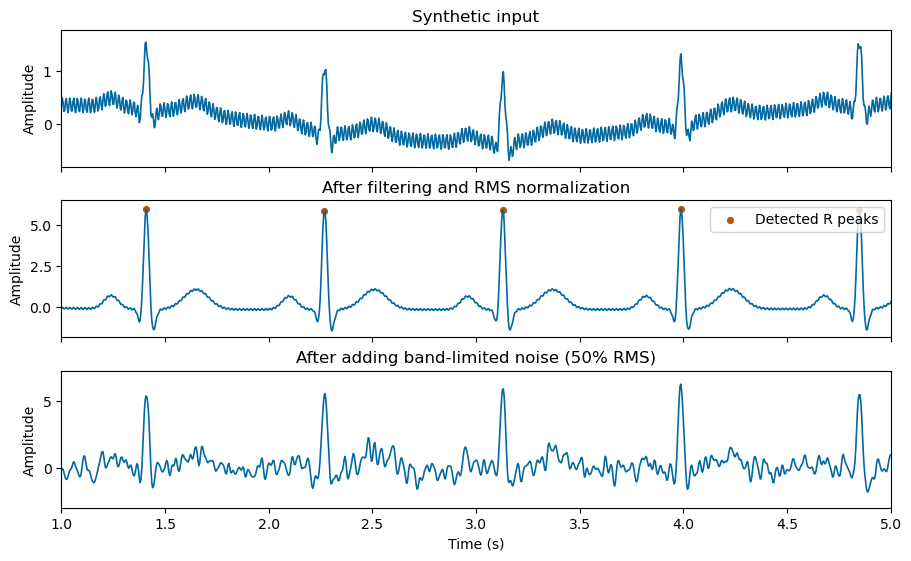

In [4]:
# Synthetic demonstration: illustrates the filter without exposing any participant waveform.
t = np.arange(10 * SAMPLE_RATE) / SAMPLE_RATE
raw_example = 0.35 * np.sin(2*np.pi*0.25*t) + 0.14 * np.sin(2*np.pi*55*t)
for center in np.arange(0.55, 9.8, 0.86):
    for shift, amp, width in [(-0.17, 0.16, 0.035), (-0.025, -0.28, 0.012),
                              (0, 1.35, 0.014), (0.025, -0.37, 0.016), (0.24, 0.24, 0.06)]:
        raw_example += amp * np.exp(-0.5 * ((t - center - shift) / width)**2)
filtered = prepare_signal(raw_example, SAMPLE_RATE)
peaks = r_peaks(filtered)
stress_example = perturb(filtered, "band-noise", 0.50, query_rng("synthetic", SEED))

fig, axes = plt.subplots(3, 1, figsize=(9, 5.5), sharex=True, layout="constrained")
for ax, signal, title in zip(axes, (raw_example, filtered, stress_example),
                             ("Synthetic input", "After filtering and RMS normalization",
                              "After adding band-limited noise (50% RMS)")):
    ax.plot(t, signal, lw=1.2, color="#0369a1")
    ax.set(title=title, xlim=(1, 5), ylabel="Amplitude")
axes[1].scatter(t[peaks], filtered[peaks], s=17, color="#b45309", label="Detected R peaks")
axes[1].legend(loc="upper right")
axes[-1].set_xlabel("Time (s)")
plt.show()

## 2. Baseline identification and verification
PCA uses spectral power, autocorrelation, amplitude summaries and estimated RR intervals. The CNN learns 64-dimensional embeddings. Both score cosine similarity to enrollment templates. Direct methods compare whole waveforms with normalized cross-correlation or banded DTW. DTW is paired with the other methods on the same ten-person Heartprint subsets.

Identification ranks the gallery (top-1 and macro-F1). Verification compares a claimed template to the query (AUC and EER); operational FAR/FRR use a threshold selected on validation. The selected impostor claims are shared across methods within each cohort.

In [5]:
def training_device(dataset):
    if DEVICE != "auto":
        return DEVICE
    return "cpu" if dataset == "ecg-id" else "auto"


def fit(dataset, protocol, method, out, augment=False):
    common = (PREPARED / dataset, "--protocol", protocol, "--out", out)
    if method == "pca":
        cli(out / "fit.log", "baseline", *common, "--dimensions", 16)
    else:
        augmentation = ("--augment",) if augment else ()
        cli(out / "fit.log", "train", *common, "--device", training_device(dataset),
            "--epochs", EPOCHS, "--batch-size", 32, "--seed", SEED, *augmentation)


def evaluate_job(dataset, protocol, method, out, fit_dir=None, cap=None, kind=None, level=None):
    opts = []
    if fit_dir is not None:
        opts.extend(("--model-run", fit_dir))
    if cap is not None:
        opts.extend(("--max-participants", cap))
    if level is not None:
        opts.extend(("--query-noise", kind, "--noise-rms", level))
    cli(out / "eval.log", "evaluate", PREPARED / dataset, "--protocol", protocol, "--method", method,
        "--out", out, "--seed", SEED, "--negatives", 10, *opts)
    return read_json(out / "metrics.json")


if not REUSE:
    for dataset in DATASETS:
        for protocol in PROTOCOLS:
            for method in ("pca", "cnn"):
                fit(dataset, protocol, method, BENCH / dataset / protocol / method)
        print("Models trained:", TITLES[dataset], flush=True)

baseline = []
for dataset, protocol, method, cap in baseline_jobs():
    out = baseline_path(BENCH, dataset, protocol, method, cap)
    if REUSE:
        result = read_json(out / "metrics.json")
    else:
        fit_dir = BENCH / dataset / protocol / method if method in ("pca", "cnn") else None
        effective_cap = 10 if MODE == "smoke" else cap
        result = evaluate_job(dataset, protocol, method, out, fit_dir=fit_dir, cap=effective_cap)
    baseline.append(dict(dataset=dataset, protocol=protocol, method=method,
                         group="Main" if cap is None else "Matched subset", **result["test"]))
baseline = pd.DataFrame(baseline)
print(f"Baseline evaluations: {len(baseline)}")

Baseline evaluations: 22


In [6]:
def display_results(frame, keys):
    fields = ["gallery_people", "queries", "top1", "macro_f1", "roc_auc", "eer", "far", "frr"]
    frame = frame.copy()
    frame["dataset"] = frame["dataset"].map(TITLES)
    frame["method"] = frame["method"].map(METHODS)
    for name in fields:
        if name not in frame:
            frame[name] = np.nan
    view = frame[keys + fields].rename(columns={"gallery_people": "Gallery", "roc_auc": "AUC",
                                               "top1": "Top-1", "macro_f1": "Macro-F1", "eer": "EER",
                                               "far": "FAR", "frr": "FRR"})
    display(view.style.hide(axis="index").format({k: "{:.1%}" for k in
                ("Top-1", "Macro-F1", "AUC", "EER", "FAR", "FRR")}, na_rep="—"))


main = baseline[baseline.group == "Main"]
display_results(main, ["dataset", "protocol", "method"])
display(Markdown("**Matched ten-person Heartprint subsets**"))
display_results(baseline[baseline.group == "Matched subset"], ["dataset", "protocol", "method"])

dataset,protocol,method,Gallery,queries,Top-1,Macro-F1,AUC,EER,FAR,FRR
ECG-ID,known,PCA,20,83,45.8%,40.7%,89.9%,16.9%,9.9%,33.7%
ECG-ID,known,1D-CNN,20,83,28.9%,20.6%,76.0%,27.7%,35.2%,25.3%
ECG-ID,unseen,PCA,4,12,91.7%,90.0%,94.4%,8.3%,8.3%,8.3%
ECG-ID,unseen,1D-CNN,4,12,66.7%,62.5%,88.0%,16.7%,13.9%,25.0%
Heartprint,known,PCA,197,924,16.2%,13.0%,85.0%,22.3%,9.6%,39.7%
Heartprint,known,1D-CNN,197,924,6.6%,5.8%,77.9%,29.5%,23.8%,35.3%
Heartprint,known,Cross-correlation,197,924,2.1%,1.6%,60.2%,42.2%,23.3%,61.4%
Heartprint,unseen,PCA,39,176,40.3%,35.3%,86.6%,22.2%,21.4%,22.7%
Heartprint,unseen,1D-CNN,39,176,58.5%,53.3%,93.5%,13.4%,15.5%,12.5%
Heartprint,unseen,Cross-correlation,39,176,9.7%,8.1%,61.3%,43.2%,41.0%,45.5%


**Matched ten-person Heartprint subsets**

dataset,protocol,method,Gallery,queries,Top-1,Macro-F1,AUC,EER,FAR,FRR
Heartprint,known,PCA,10,41,48.8%,41.9%,81.2%,26.6%,5.1%,68.3%
Heartprint,known,1D-CNN,10,41,22.0%,28.4%,65.1%,39.0%,37.4%,43.9%
Heartprint,known,Cross-correlation,10,41,14.6%,11.3%,56.6%,45.8%,29.8%,63.4%
Heartprint,known,DTW,10,41,26.8%,32.1%,74.9%,33.3%,18.4%,48.8%
Heartprint,unseen,PCA,10,38,44.7%,39.1%,75.5%,31.0%,25.4%,36.8%
Heartprint,unseen,1D-CNN,10,38,84.2%,83.3%,95.7%,11.1%,13.5%,7.9%
Heartprint,unseen,Cross-correlation,10,38,13.2%,10.7%,57.2%,43.9%,42.4%,44.7%
Heartprint,unseen,DTW,10,38,28.9%,24.9%,74.4%,31.3%,54.1%,7.9%


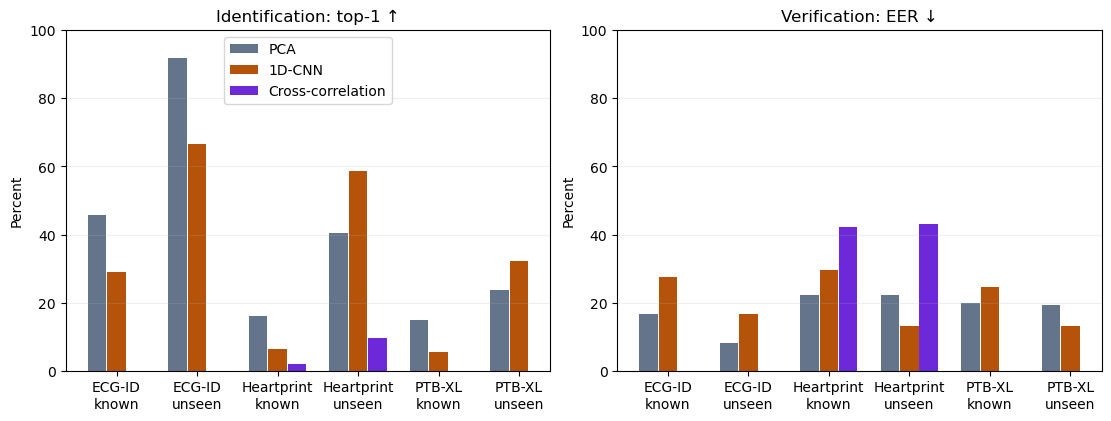

In [7]:
# The gallery size changes across scenarios, so compare models within each category.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), layout="constrained")
groups = [(d, p) for d in DATASETS for p in PROTOCOLS]
positions = np.arange(len(groups))
for ax, key, title in zip(axes, ("top1", "eer"), ("Identification: top-1 ↑", "Verification: EER ↓")):
    for i, method in enumerate(("pca", "cnn", "correlation")):
        vals = main[main.method == method].set_index(["dataset", "protocol"])[key]
        ax.bar(positions + (i - 1) * 0.24, [100 * vals.get(group, np.nan) for group in groups],
               width=0.23, color=COLORS[method], label=METHODS[method])
    ax.set(title=title, ylabel="Percent", xticks=positions,
           xticklabels=[f"{TITLES[d]}\n{p}" for d, p in groups], ylim=(0, 100))
    ax.grid(axis="y", alpha=0.2)
axes[0].legend()
plt.show()

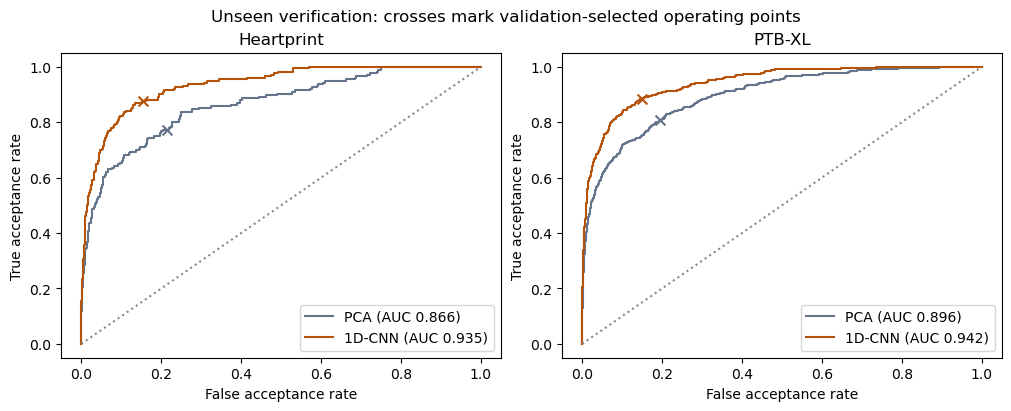

In [8]:
roc_datasets = [d for d in DATASETS if d in ("heartprint", "ptb-xl")]
fig, axes = plt.subplots(1, len(roc_datasets), squeeze=False, figsize=(5 * len(roc_datasets), 4),
                         layout="constrained")
for ax, dataset in zip(axes[0], roc_datasets):
    for method in ("pca", "cnn"):
        out = baseline_path(BENCH, dataset, "unseen", method, None)
        pairs = pd.read_csv(out / "test_pairs.csv")
        fpr, tpr, _ = roc_curve(pairs.genuine, pairs.score)
        results = read_json(out / "metrics.json")["test"]
        ax.plot(fpr, tpr, color=COLORS[method], label=f"{METHODS[method]} (AUC {results['roc_auc']:.3f})")
        if "far" in results:
            ax.scatter(results["far"], 1 - results["frr"], color=COLORS[method], marker="x", s=50)
    ax.plot([0, 1], [0, 1], ":", color="#888")
    ax.set(title=TITLES[dataset], xlabel="False acceptance rate", ylabel="True acceptance rate")
    ax.legend(loc="lower right")
fig.suptitle("Unseen verification: crosses mark validation-selected operating points")
plt.show()

## 3. Noise robustness and augmentation
For unseen participants, compare PCA, the original CNN and an identical CNN trained with augmentation. Only test queries receive synthetic residual drift (0.25 Hz) or Gaussian noise filtered at 0.5–40 Hz. Noise RMS is 25% or 50% of signal RMS. Enrollment signals and each model's clean-validation threshold remain fixed.

In [9]:
stress = []
ready = set()
for dataset, model, kind, level in stress_jobs():
    fit_dir = (STRESS / dataset / "cnn-aug" if model == "cnn-aug"
               else BENCH / dataset / "unseen" / model)
    if not REUSE and model == "cnn-aug" and dataset not in ready:
        fit(dataset, "unseen", "cnn", fit_dir, augment=True)
        ready.add(dataset)
        print("Augmented model trained:", TITLES[dataset], flush=True)
    out = stress_path(STRESS, dataset, model, kind, level)
    method = "cnn" if model == "cnn-aug" else model
    if REUSE:
        result = read_json(out / "metrics.json")
    else:
        result = evaluate_job(dataset, "unseen", method, out, fit_dir=fit_dir,
                              cap=10 if MODE == "smoke" else None, kind=kind, level=level)
    stress.append(dict(dataset=dataset, method=model, noise=kind, rms=level or 0,
                       threshold=result["threshold_from_validation"], **result["test"]))
stress = pd.DataFrame(stress)
assert stress.groupby(["dataset", "method"]).threshold.nunique().eq(1).all()
print(f"Robustness evaluations: {len(stress)}")

Robustness evaluations: 30


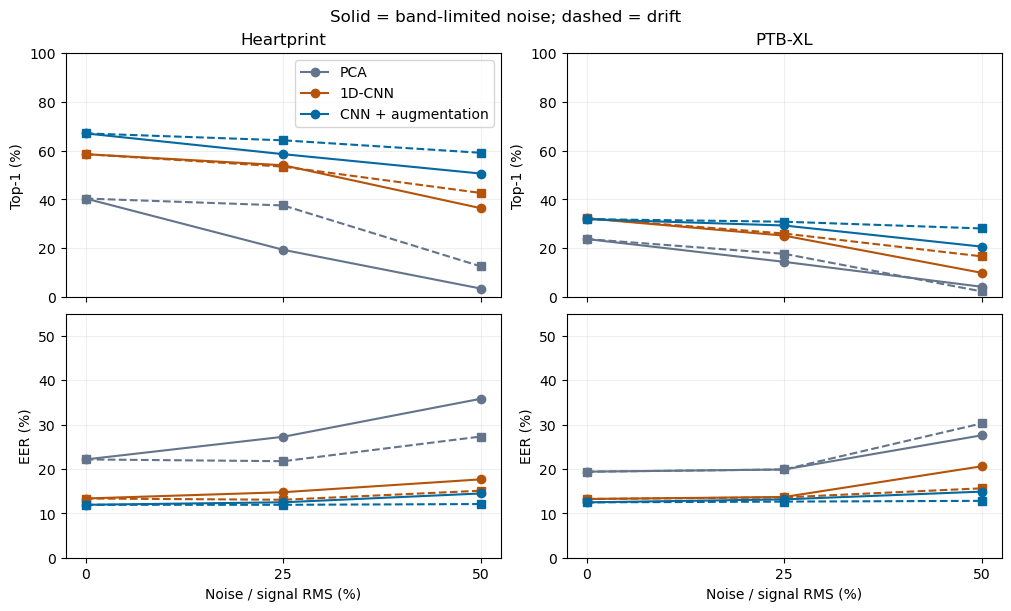

dataset,method,noise,Gallery,queries,Top-1,Macro-F1,AUC,EER,FAR,FRR
Heartprint,PCA,drift,39,176,12.5%,5.6%,79.8%,27.3%,11.9%,59.7%
Heartprint,PCA,band-noise,39,176,3.4%,0.8%,67.8%,35.9%,16.0%,63.1%
Heartprint,1D-CNN,drift,39,176,42.6%,36.7%,91.8%,15.1%,13.9%,16.5%
Heartprint,1D-CNN,band-noise,39,176,36.4%,33.0%,89.3%,17.7%,11.2%,28.4%
Heartprint,CNN + augmentation,drift,39,176,59.1%,55.9%,93.8%,12.1%,14.3%,10.2%
Heartprint,CNN + augmentation,band-noise,39,176,50.6%,47.8%,91.9%,14.5%,14.1%,15.3%
PTB-XL,PCA,drift,408,577,2.3%,0.8%,76.2%,30.3%,17.4%,49.6%
PTB-XL,PCA,band-noise,408,577,4.2%,2.3%,80.2%,27.6%,15.6%,44.9%
PTB-XL,1D-CNN,drift,408,577,16.6%,11.4%,92.3%,15.6%,13.8%,17.5%
PTB-XL,1D-CNN,band-noise,408,577,9.9%,6.3%,87.4%,20.6%,13.0%,31.2%


In [10]:
fig, axes = plt.subplots(2, len(roc_datasets), squeeze=False, figsize=(5 * len(roc_datasets), 6),
                         sharex=True, layout="constrained")
for col, dataset in enumerate(roc_datasets):
    for method in ("pca", "cnn", "cnn-aug"):
        subset = stress[(stress.dataset == dataset) & (stress.method == method)]
        for row, metric in enumerate(("top1", "eer")):
            for kind, lines, marker in (("band-noise", "-", "o"), ("drift", "--", "s")):
                series = subset[subset.noise.isin(("clean", kind))].sort_values("rms")
                axes[row, col].plot(series.rms * 100, series[metric] * 100, linestyle=lines, marker=marker,
                                    color=COLORS[method], label=METHODS[method] if kind == "band-noise" else None)
    axes[0, col].set(title=TITLES[dataset], ylabel="Top-1 (%)", ylim=(0, 100))
    axes[1, col].set(xlabel="Noise / signal RMS (%)", ylabel="EER (%)", xticks=[0, 25, 50], ylim=(0, 55))
    for ax in axes[:, col]:
        ax.grid(alpha=0.2)
axes[0, 0].legend()
fig.suptitle("Solid = band-limited noise; dashed = drift")
plt.show()

heavy = stress[stress.rms == 0.50]
display_results(heavy, ["dataset", "method", "noise"])

## 4. Findings
The statements below are calculated from the test files used in this notebook. Smoke-mode numbers are for pipeline checking only. Comparisons are within a dataset and protocol.

In [11]:
lines = []
for dataset in DATASETS:
    rows = main[(main.dataset == dataset) & (main.protocol == "unseen")].set_index("method")
    pca, cnn = rows.loc["pca"], rows.loc["cnn"]
    lines.append(f"- **{TITLES[dataset]}, unseen ({cnn.gallery_people} people, {cnn.queries} queries):** "
                 f"PCA vs CNN top-1 {pca.top1:.1%} vs {cnn.top1:.1%}; "
                 f"EER {pca.eer:.1%} vs {cnn.eer:.1%}.")
    if cnn.gallery_people <= 4:
        lines[-1] += " This cohort is too small for a strong comparative conclusion."
    known = main[(main.dataset == dataset) & (main.protocol == "known")].set_index("method")
    lines.append(f"- **{TITLES[dataset]}, known:** PCA vs CNN top-1 "
                 f"{known.loc['pca','top1']:.1%} vs {known.loc['cnn','top1']:.1%}.")
for dataset in roc_datasets:
    rows = heavy[(heavy.dataset == dataset) & (heavy.noise == "band-noise")].set_index("method")
    old, aug = rows.loc["cnn"], rows.loc["cnn-aug"]
    lines.append(f"- **{TITLES[dataset]}, strong band-limited noise:** augmentation changed top-1 "
                 f"from {old.top1:.1%} to {aug.top1:.1%}, and EER from {old.eer:.1%} to {aug.eer:.1%}. "
                 f"At the validation thresholds, FAR was {old.far:.1%} → {aug.far:.1%}, "
                 f"and FRR was {old.frr:.1%} → {aug.frr:.1%}.")
display(Markdown("\n".join(lines)))

- **ECG-ID, unseen (4 people, 12 queries):** PCA vs CNN top-1 91.7% vs 66.7%; EER 8.3% vs 16.7%. This cohort is too small for a strong comparative conclusion.
- **ECG-ID, known:** PCA vs CNN top-1 45.8% vs 28.9%.
- **Heartprint, unseen (39 people, 176 queries):** PCA vs CNN top-1 40.3% vs 58.5%; EER 22.2% vs 13.4%.
- **Heartprint, known:** PCA vs CNN top-1 16.2% vs 6.6%.
- **PTB-XL, unseen (408 people, 577 queries):** PCA vs CNN top-1 23.7% vs 32.2%; EER 19.4% vs 13.2%.
- **PTB-XL, known:** PCA vs CNN top-1 15.0% vs 5.7%.
- **Heartprint, strong band-limited noise:** augmentation changed top-1 from 36.4% to 50.6%, and EER from 17.7% to 14.5%. At the validation thresholds, FAR was 11.2% → 14.1%, and FRR was 28.4% → 15.3%.
- **PTB-XL, strong band-limited noise:** augmentation changed top-1 from 9.9% to 20.6%, and EER from 20.6% to 14.9%. At the validation thresholds, FAR was 13.0% → 13.9%, and FRR was 31.2% → 15.3%.

These experiments use one split seed, one training seed and within-dataset transfer. Gallery size differs between known and unseen protocols, so it is not possible to attribute the difference solely to whether a participant was seen during training. The known validation queries come from the enrollment session, which can make the threshold less suitable for later sessions. Synthetic noise tests sensitivity at the model input; it does not establish robustness to a new sensor or real-world interference. Random impostor claims do not model a determined attack. This is a course experiment, not a deployed authentication system.

Primary data sources: [ECG-ID](https://physionet.org/content/ecgiddb/1.0.0/), [Heartprint](https://doi.org/10.6084/m9.figshare.20105354.v3), [PTB-XL](https://physionet.org/content/ptb-xl/1.0.3/). See [protocol](PROTOCOL.md), [baseline results](RESULTS.md) and [robustness results](ROBUSTNESS.md) for detail.